# 05 · Бейзлайны B1–B4

Шаг 6 плана. Четыре бейзлайна считаются только по данным до cutoff:
B1 — историческая сумма; B2 — среднее по когорте; B3 — мультипликатор
(медиана `revenue_6m/revenue_60d` по когортам, перенос на 12 мес через `C(k)`);
B4 — сумма когортной кривой выживания с ассертом на убывание.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import json
from inspect import signature
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, PROCESSED, RANDOM_SEED, figures
from features import (CUTOFF_DATE, HORIZON_MONTHS, B3_T_DAYS, B3_FIT_MONTHS,
                      DAYS_IN_AGE_MONTH, split_transactions, calibration_features,
                      calibration_revenue, build_target, lifecycle_transactions,
                      first_purchase_dates, pre_first_mask, customer_country,
                      cohort_tables, pooled_curve, extend_survival,
                      extend_cumulative_revenue, age_months)
from metrics import (gini, top_capture, top_lift, decile_capture, lorenz_points,
                     mae, rmse, calibration_ratio, model_metrics, bootstrap_ci,
                     bootstrap_diff, calibration_by, coverage_at_top,
                     smallest_segment_for_coverage, shrink_predictions)
from models import (fit_bgnbd, fit_mbg_nbd, fit_pareto_nbd, fit_gamma_gamma,
                    bgnbd_loglik, bgnbd_expected_purchases, mbg_nbd_loglik,
                    mbg_nbd_expected_purchases, pareto_nbd_loglik,
                    pareto_nbd_expected_purchases, gamma_gamma_loglik,
                    gamma_gamma_mean, gamma_gamma_conditional_spend,
                    monthly_expected_purchases, discounted_revenue, aic)
from plots import (plot_split_timeline, plot_lorenz, plot_model_comparison,
                   plot_calibration_by_decile, plot_horizon, plot_segments,
                   plot_shrinkage, plot_posterior)
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
tx = pd.read_parquet(PROCESSED / 'transactions.parquet')

split = pd.read_parquet(PROCESSED / 'ltv_split.parquet')
cal, hold = split_transactions(tx)
idx = split.index
y = split.revenue_holdout.to_numpy(float)


## B1 и B2

In [2]:
split['B1'] = split.revenue_cal
cm = split.groupby('cohort')['revenue_cal'].agg(['mean', 'size'])
cm.loc[cm['size'] < 30, 'mean'] = split.revenue_cal.mean()
split['B2'] = split.cohort.map(cm['mean']).astype(float)
print('B2: когорт с <30 клиентов заменено на общее среднее:', int((cm['size'] < 30).sum()))


B2: когорт с <30 клиентов заменено на общее среднее: 0


## B3: мультипликатор

12-месячный множитель нельзя оценить без утечки: первое 12-месячное окно когорт
2010-01…2010-11 заканчивается после cutoff. Оцениваю 6-месячный множитель на
когортах, у которых эти 6 месяцев наблюдаются до cutoff, и переношу на 12 месяцев
через когортную кривую `C(k)`. `t = 60` дней: 30 дней дают более шумное отношение.

In [3]:
cal_lc = lifecycle_transactions(tx)
cal_lc = cal_lc[cal_lc.date < CUTOFF_DATE]
cal_sales = cal_lc[~cal_lc.is_cancel]
first = split.first_purchase
age_days = (CUTOFF_DATE - first).dt.days

def window_rev(days):
    m = cal_sales.assign(lo=cal_sales.customer_id.map(first),
                         hi=cal_sales.customer_id.map(first + pd.Timedelta(days=days)))
    m = m[(m.date >= m['lo']) & (m.date < m['hi'])]
    return m.groupby('customer_id')['revenue'].sum().reindex(idx, fill_value=0.0)

rev_t = window_rev(B3_T_DAYS)
rev_6m = window_rev(B3_FIT_MONTHS * 30)
rev_t_adj = rev_t * B3_T_DAYS / np.minimum(age_days.clip(lower=1), B3_T_DAYS)
elig = age_days >= B3_FIT_MONTHS * 30
ratio = rev_6m / rev_t.replace(0, np.nan)
m_cohort = ratio[elig].groupby(split.loc[elig, 'cohort']).median()
pooled_m = ratio[elig].median()
split['B3_multiplier'] = split.cohort.map(m_cohort).fillna(pooled_m)
print('B3: pooled multiplier', round(pooled_m, 3), '· когорт с оценкой', len(m_cohort))
print(m_cohort.round(3).to_dict())


B3: pooled multiplier 1.532 · когорт с оценкой 7
{'2009-12': 1.756, '2010-01': 1.645, '2010-02': 1.414, '2010-03': 1.199, '2010-04': 1.216, '2010-05': 1.0, '2010-06': 1.37}


In [4]:
size, ret, rpc = cohort_tables(cal, split, max_age=12, include_cancellations=True)
inc_pool = pooled_curve(rpc, size, exclude_first=True)
C = extend_cumulative_revenue(inc_pool, max_age=24)
a = (age_days // DAYS_IN_AGE_MONTH).clip(0, 12).astype(int)
c_a = C.reindex(a.values).to_numpy()
c_a12 = C.reindex((a + 12).clip(upper=24).values).to_numpy()
split['B3'] = rev_t_adj.to_numpy() * split.B3_multiplier.to_numpy() * (c_a12 - c_a) / C.loc[6]
split.loc[~np.isfinite(split.B3) | (split.B3 < 0), 'B3'] = split.loc[~np.isfinite(split.B3) | (split.B3 < 0), 'B2']
print('C(6)=', round(C.loc[6], 1), '· C(12)=', round(C.loc[12], 1), '· C(24)=', round(C.loc[24], 1))
assert (np.diff(C.to_numpy()) >= -1e-9).all(), 'C(k) должна быть неубывающей'


C(6)= 1156.3 · C(12)= 2199.0 · C(24)= 4403.0


## B4: сумма когортной кривой выживания

Сырая retention по когортам немонотонна: на возрастах 6–9 она растёт из-за состава
когорт (короткие когорты выживают лучше). Для B4 нужна кривая выживания, поэтому
беру кумулятивный минимум и продлеваю геометрическим хвостом. Ассерт на убывание —
в `extend_survival` и ниже.

In [5]:
ret_pool = pooled_curve(ret, size, exclude_first=True)
S = extend_survival(ret_pool, max_age=24)
assert (np.diff(S.to_numpy()) <= 1e-12).all(), 'survival curve должна убывать'
active_blocks = (cal_sales.assign(age=age_months(cal_sales, first))
                 .groupby('customer_id')['age'].nunique().reindex(idx, fill_value=1).clip(lower=1))
arpu = split.revenue_cal / active_blocks
split['B4'] = [arpu.iloc[i] * sum(S.loc[k] for k in range(int(a.iloc[i]), min(int(a.iloc[i]) + 12, 25)))
               for i in range(len(split))]
print('S(1..12):', S.loc[1:12].round(3).to_dict())


S(1..12): {1: 0.224, 2: 0.224, 3: 0.224, 4: 0.224, 5: 0.219, 6: 0.219, 7: 0.219, 8: 0.219, 9: 0.219, 10: 0.219, 11: 0.219, 12: 0.219}


## Таблица «бейзлайн × метрика»

In [6]:
rows = []
for m in ['B1', 'B2', 'B3', 'B4']:
    rows.append({'model': m, **model_metrics(y, split[m].to_numpy(float))})
base_table = pd.DataFrame(rows).set_index('model')
base_table.round(4)


,gini,top10_capture,top10_lift,top20_capture,mae,rmse,calibration_ratio
model,,,,,,,
B1,0.7036,0.6096,6.0961,0.7388,1080.5227,4066.2918,1.2419
B2,0.3478,0.2762,2.7619,0.4399,2112.9004,7960.4240,1.2419
B3,0.5932,0.5065,5.0653,0.6416,2128.2723,9366.1558,1.7295
B4,0.6282,0.5246,5.2464,0.6651,1465.9200,6294.1502,0.8647


In [7]:
split[['B1', 'B2', 'B3', 'B4', 'B3_multiplier']].to_parquet(PROCESSED / 'baselines.parquet')
base_table.to_csv(PROCESSED / 'baseline_metrics.csv')
assert split[['B1', 'B2', 'B3', 'B4']].notna().all().all()
assert (split[['B1', 'B2', 'B4']] >= 0).all().all()


## Кривые Лоренца бейзлайнов

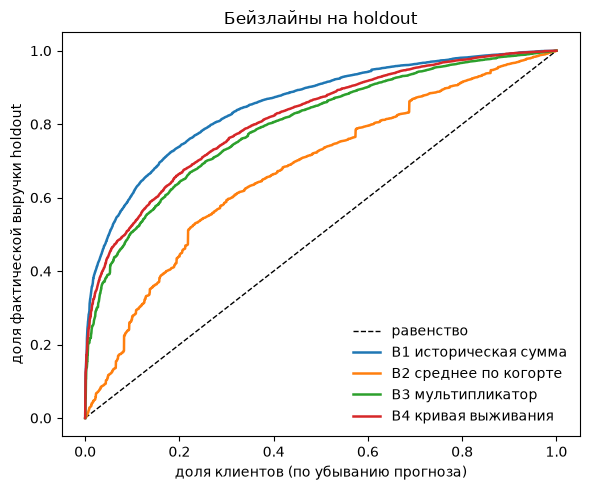

In [8]:
plot_lorenz(y, {'B1 историческая сумма': split.B1, 'B2 среднее по когорте': split.B2,
                 'B3 мультипликатор': split.B3, 'B4 кривая выживания': split.B4},
           FIG / '08-baseline-lorenz.png', title='Бейзлайны на holdout')
plt.show()


B1 — сильный конкурент: калибровочная выручка несёт всю информацию о размере
клиента. B2 теряет индивидуальность и падает по Gini. B3 и B4 — отраслевые бейзлайны;
их сравнение с BG/NBD идёт в ноутбуке 08.